# Figure 2: coefficient non-Gaussianity

Section 3.4, `fig:kurtosis`. The excess kurtosis of every spherical-harmonic
coefficient over the $6.4\times10^5$ surfaces the auto-encoder was trained on,
laid out on the $(\ell, m)$ grid, with the summary moments the section quotes.

The moments are accumulated in one streaming pass rather than from a stacked
array: 640,000 surfaces at float64 is 4.9 GB, and the pool sits on a spinning
disk where the reads, not the arithmetic, are the cost. The pass is cached, so
re-running this notebook is immediate.

One packing note: `coeffs_to_real` is block ordered,
$[\,m{=}0 \mid \mathrm{Re}\,m{>}0 \mid \mathrm{Im}\,m{>}0\,]$, not
flat in `lm_to_idx`, so the $(\ell, m)$ scatter below follows that layout:
the $m > 0$ half of the map is the real parts, the $m < 0$ half the
imaginary parts, exactly as in the legacy figure.

## Imports

In [1]:
from scipy import stats

from _setup import *


## Setup

The grouped training pool, truncated to the set the auto-encoder saw. The
explicit holdout lives in its own directory, a sibling of this one, so nothing
here is evaluation data.

The pool holds $1.28\times10^6$ surfaces and the moments are the same over
either range to well inside the Monte Carlo floor, so the truncation is a
statement about which surfaces the figure claims to describe, not an
approximation.

In [2]:
# The surfaces the auto-encoder was trained on: the first N_POOL of the
# grouped pool, matching the 6.4e5 quoted in the datasets section.
POOL = os.path.join(HOLDOUT, '..', 'surfaces')
N_POOL = 640_000
CHUNK = 4000           # surfaces held in memory at once
CACHE = os.path.join(CACHES, 'fig02_moments.npz')

## Loading

In [3]:
names = sorted(os.listdir(POOL))[:N_POOL]
sidx = np.fromiter((int(n[8:15]) for n in names), np.int64, len(names))
assert sidx[0] == 0 and sidx[-1] == N_POOL - 1, 'pool is not contiguous'
nspot = (pd.read_csv(os.path.join(POOL, '..', 'metadata.csv'),
                     usecols=['surface_idx', 'n_spots'])
         .drop_duplicates('surface_idx')      # the catalogue is written twice
         .set_index('surface_idx')
         .loc[sidx, 'n_spots'].values.astype(np.int8))


def accumulate(shift):
    """
    Shifted power sums of the real-packed coefficients, per spot count, in one
    pass over the pool.

    Shifted rather than raw: the fourth power of a variable with a large mean
    loses most of its significant digits, and the monopole sits at 2 sqrt(pi).
    Keeping the spot counts apart costs nothing and lets any subset be recovered
    as a partial sum, so the breakdown below needs no second pass.
    """
    cnt = np.zeros(11)
    S = np.zeros((4, 11, (L_MAX + 1) ** 2))
    for a in range(0, len(names), CHUNK):
        b = min(a + CHUNK, len(names))
        X = np.empty((b - a, (L_MAX + 1) ** 2))
        for j, n in enumerate(names[a:b]):
            X[j] = coeffs_to_real(np.load(os.path.join(POOL, n)))
        X -= shift
        g = nspot[a:b] - 1
        X2 = X * X
        for k, P in enumerate((X, X2, X2 * X, X2 * X2)):
            for gi in range(11):
                sel = g == gi
                if sel.any():
                    S[k, gi] += P[sel].sum(axis=0)
                    if k == 0:
                        cnt[gi] += sel.sum()
    return cnt, S


os.makedirs(CACHES, exist_ok=True)
# The guard checks the surface count in the cache, not just its existence, so
# changing N_POOL or the packing invalidates it instead of silently reusing
# moments for a different set.
z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and z['cnt'].sum() == N_POOL:
    cnt, S, shift = z['cnt'], z['S'], z['shift']
    print(f'moments read from {os.path.relpath(CACHE, REPO)}')
else:
    shift = np.mean([coeffs_to_real(np.load(os.path.join(POOL, n)))
                     for n in names[:CHUNK]], axis=0)
    cnt, S = accumulate(shift)      # ~13 min, 640k reads off a spinning disk
    np.savez(CACHE, cnt=cnt, S=S, shift=shift)
    print(f'moments written to {os.path.relpath(CACHE, REPO)}')
print(f'{cnt.sum():,.0f} surfaces, spot counts {nspot.min()}-{nspot.max()}')

moments written to caches/fig02_moments.npz
640,000 surfaces, spot counts 1-11


## Moments

Fisher convention throughout: excess kurtosis, Gaussian = 0. The central
moments are reconstructed from the shifted power sums, so any subset -- the
whole training set, or one spot count -- is a partial sum and needs no further
reading. The packed layout is then scattered onto the $(\ell, m)$ grid; the
sign of the $m < 0$ (imaginary) half and the factors of two in the legacy
packing do not move either moment.

In [4]:
def moments(spots=None):
    """
    (skewness, excess kurtosis, N) per packed coefficient.

    spots selects one spot count (1-11); None pools all of them.
    """
    gi = slice(None) if spots is None else slice(spots - 1, spots)
    n = cnt[gi].sum()
    a1, a2, a3, a4 = (S[k, gi].sum(axis=0) / n for k in range(4))
    m2 = a2 - a1 ** 2
    m3 = a3 - 3 * a1 * a2 + 2 * a1 ** 3
    m4 = a4 - 4 * a1 * a3 + 6 * a1 ** 2 * a2 - 3 * a1 ** 4
    return m3 / m2 ** 1.5, m4 / m2 ** 2 - 3, n


n_m0 = L_MAX + 1
pairs = [(l, m) for l in range(L_MAX + 1) for m in range(1, l + 1)]


def lm_grid(stat):
    """The packed vector scattered onto the (l, m) plane."""
    G = np.full((L_MAX + 1, 2 * L_MAX + 1), np.nan)
    G[np.arange(n_m0), L_MAX] = stat[:n_m0]
    for j, (l, m) in enumerate(pairs):
        G[l, L_MAX + m] = stat[n_m0 + j]                # real parts
        G[l, L_MAX - m] = stat[n_m0 + len(pairs) + j]   # imaginary parts
    return G


skew, kurt, N_SURF = moments()
K = lm_grid(kurt)
kurt_low = np.nanmedian(K[:6])
kurt_high = np.nanmedian(K[25:])
print(f'kurtosis medians: global {np.nanmedian(K):.3f}, '
      f'l <= 5 {kurt_low:.3f}, l >= 25 {kurt_high:.3f}')

kurtosis medians: global 1.525, l <= 5 1.162, l >= 25 1.692


## The figure

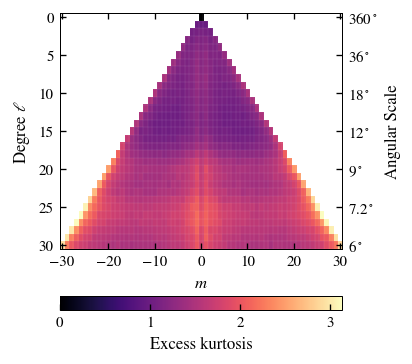

In [5]:
# Label and tick sizes. The figure is drawn at the printed column width, so
# these are the sizes that reach the page: 10 pt labels and 9 pt ticks sit at
# or above the MNRAS body size, with no downscaling to shrink them.
LAB, TICK = 10, 9

fig, ax = plt.subplots(figsize=(COL, COL * 0.88))
im = ax.imshow(K, origin='upper',
               extent=[-L_MAX - 0.5, L_MAX + 0.5, L_MAX + 0.5, -0.5],
               aspect='auto', cmap='magma', vmin = 0)

cb = fig.colorbar(im, ax=ax, orientation='horizontal', pad=0.02,
                  fraction=0.06)
cb.set_label('Excess kurtosis', fontsize=LAB)
cb.ax.tick_params(labelsize=TICK)

ax.set_xlabel(r'$m$', fontsize=LAB)
ax.set_ylabel(r'Degree $\ell$', fontsize=LAB)
ax.set_xticks(np.arange(-L_MAX, L_MAX + 1, 10))
ax.set_yticks(np.arange(0, L_MAX + 1, 5))
ax.tick_params(labelsize=TICK, right=False)

# One white gridline per cell, so individual (l, m) coefficients stay legible.
ax.set_xticks(np.arange(-L_MAX - 0.5, L_MAX + 1.5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, L_MAX + 1.5, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=0.2, alpha=0.25)
ax.tick_params(which='minor', length=0)

secax = ax.twinx()
secax.set_ylim(ax.get_ylim())
secax.set_yticks([0, 5, 10, 15, 20, 25, 30])
secax.set_yticklabels([r'360$^\circ$', r'36$^\circ$', r'18$^\circ$',
                       r'12$^\circ$', r'9$^\circ$', r'7.2$^\circ$',
                       r'6$^\circ$'])
secax.set_ylabel('Angular Scale', fontsize=LAB)
secax.tick_params(direction='in', labelsize=TICK)


## Saving and caption numbers

In [6]:
save_fig(fig, 'fig02_kurtosis')
m0 = np.abs(skew[:n_m0])
mnz = np.abs(skew[n_m0:])
print(f'{N_SURF:,.0f} training surfaces, pool {POOL}')
print(f'skewness: median |g1| {np.median(m0):.4f} at m = 0, '
      f'{np.median(mnz):.4f} at m != 0')
print(f'excess kurtosis: global median {np.nanmedian(K):.3f}, '
      f'l <= 5 median {kurt_low:.3f}, l >= 25 median {kurt_high:.3f}')
print(f'Gaussian MC noise floor at this sample size: '
      f'skew ~ {np.sqrt(6 / N_SURF):.5f}, '
      f'kurt ~ {np.sqrt(24 / N_SURF):.5f}')
print(f'most leptokurtic coefficient: {np.nanmax(K):.2f}')

wrote notebooks/paper/figs/fig02_kurtosis.pdf, notebooks/paper/figs/fig02_kurtosis.png
640,000 training surfaces, pool /home/conaire/2025/Paper2Plus/starspot-sbi/../Sydney/data/fast/L30_N216_grouped/explicit_holdout/../surfaces
skewness: median |g1| 0.0512 at m = 0, 0.0042 at m != 0
excess kurtosis: global median 1.525, l <= 5 median 1.162, l >= 25 median 1.692
Gaussian MC noise floor at this sample size: skew ~ 0.00306, kurt ~ 0.00612
most leptokurtic coefficient: 3.13


## Kurtosis by spot count

The pooled figure above mixes eleven spot-count populations of differing
variance, and mixing alone lifts kurtosis above any of its components. This
separates the two: the $\ell$ trend within each fixed count, against the
overall level, which is substantially a mixture effect.

In [7]:
print(f"{'subset':>17} {'N':>9} {'global':>8} {'l<=5':>8} {'l>=25':>8}"
      f" {'max':>8} {'ratio':>7}")


def row(label, **sel):
    _, k, n = moments(**sel)
    G = lm_grid(k)
    lo, hi = np.nanmedian(G[:6]), np.nanmedian(G[25:])
    print(f'{label:>17} {n:>9,.0f} {np.nanmedian(G):8.3f} {lo:8.3f} '
          f'{hi:8.3f} {np.nanmax(G):8.3f} {hi / lo:7.2f}')


row('all')
for n in range(1, 12):
    row(f"{n} spot{'s' if n > 1 else ''}", spots=n)

# Each surface is a sum of n independent caps, so the excess kurtosis of the
# sum should fall as 1/n; the pooled value then follows from the mixture over
# the uniform spot count alone.
k1 = np.nanmedian(lm_grid(moments(spots=1)[1]))
nn = np.arange(1, 12)
print(f'\nsingle-spot median kurtosis k1 = {k1:.3f}')
print(f'pooled predicted by k1/n and the U(1,11) mixture: '
      f'{(k1 * nn.mean() + 3 * (nn ** 2).mean()) / nn.mean() ** 2 - 3:.3f}, '
      f'observed {np.nanmedian(K):.3f}')
print(f'  of which spot-count mixture alone: '
      f'{3 * (nn ** 2).mean() / nn.mean() ** 2 - 3:.3f}')

           subset         N   global     l<=5    l>=25      max   ratio
              all   640,000    1.525    1.162    1.692    3.132    1.46
           1 spot    58,133    4.212    1.988    5.138   14.078    2.58
          2 spots    58,325    2.094    1.001    2.583    7.148    2.58
          3 spots    58,384    1.391    0.643    1.692    4.663    2.63
          4 spots    57,588    1.045    0.507    1.269    3.619    2.50
          5 spots    58,232    0.833    0.379    1.021    2.920    2.69
          6 spots    58,290    0.699    0.321    0.873    2.307    2.72
          7 spots    58,375    0.596    0.275    0.734    1.972    2.67
          8 spots    57,776    0.520    0.262    0.656    1.867    2.50
          9 spots    58,166    0.461    0.210    0.572    1.628    2.73
         10 spots    58,356    0.421    0.206    0.526    1.407    2.55
         11 spots    58,375    0.382    0.181    0.469    1.271    2.59

single-spot median kurtosis k1 = 4.212
pooled predicted by k1/n